# CDO Tranches and Default Correlation: Why "AAA" Failed in 2008

**Question:** A collateralized debt obligation (CDO) pools many loans and cuts the pool's losses into slices. The equity tranche absorbs the first losses, then the mezzanine, then the senior tranches. Before 2007, most of each mortgage deal was sold as AAA. Yet a large share of the AAA mortgage securities issued in 2005–2007 was later downgraded, and many lost money. The pool's expected loss is fixed by the loans, so how did the senior tranches become so much riskier than rated? The answer is **default correlation**: it does not change how much is lost on average, but it decides *who* bears the loss.

This notebook:

1. Builds the one-factor Gaussian copula (Vasicek, 2002; Li, 2000), the industry-standard CDO model, and checks its large-pool formula against Monte Carlo.
2. Shows that raising correlation moves expected loss from the equity tranche to the senior tranches while the pool's total stays the same.
3. Measures how fragile tranche ratings are to small errors in default probability and correlation, and how large the AAA tranche can be made under each assumption.
4. Re-tranches mezzanine tranches into a CDO² and shows its AAA tranche depends on a correlation that was close to unobservable.
5. Shows senior tranches are "economic catastrophe bonds" (Coval, Jurek & Stafford, 2009). They lose only in the worst states of the economy.
6. Fits the model to 35 years of US mortgage charge-off data from FRED, with and without the crisis, and asks what the pre-crisis model said about 2009.

The stylized deal used in Sections 2–5 is a large pool of mortgages with a 5% chance of default over 5 years and a 40% loss given default, so the pool is expected to lose 2% of its notional. It is cut into equity (0–3%), mezzanine (3–7%), senior (7–15%) and super-senior (15–100%) tranches.

In [1]:
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

# Stylized mortgage pool and capital structure (5-year horizon)
PD, LGD = 0.05, 0.40           # cumulative default probability and loss given default
TRANCHES = {"Equity": (0.00, 0.03), "Mezzanine": (0.03, 0.07),
            "Senior": (0.07, 0.15), "Super senior": (0.15, 1.00)}

## 1. The one-factor Gaussian copula

Each borrower $i$ defaults if its "asset value" $A_i$ falls below a threshold. Asset values share one common factor $Z$ (the economy) and an independent idiosyncratic part:

$$A_i = \sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon_i, \qquad \text{default if } A_i < N^{-1}(p).$$

$\rho$ is the **asset correlation**. Given the state of the economy $Z$, defaults are independent, each with probability

$$p(Z) = N\!\left(\frac{N^{-1}(p) - \sqrt\rho\,Z}{\sqrt{1-\rho}}\right).$$

In a large pool the law of large numbers makes the default fraction equal $p(Z)$. Its distribution then has the closed form of Vasicek (2002):

$$P(\text{default fraction} \le x) = N\!\left(\frac{\sqrt{1-\rho}\,N^{-1}(x) - N^{-1}(p)}{\sqrt\rho}\right).$$

The left panel checks this formula against Monte Carlo pools of 100 and 1,000 loans. The right panel keeps the expected loss fixed at 2% and changes only $\rho$.

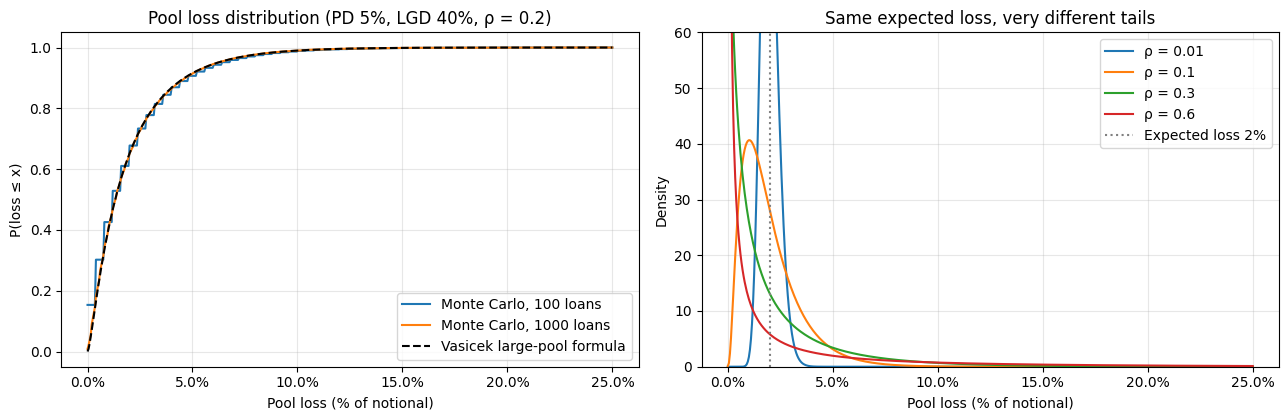

In [2]:
def cond_pd(p, rho, z):
    """Default probability of each loan given the common factor z (low z = bad economy)."""
    return norm.cdf((norm.ppf(p) - np.sqrt(rho) * z) / np.sqrt(1 - rho))


def vasicek_cdf(x, p, rho):
    """P(default fraction <= x) in an infinitely granular pool (Vasicek, 2002)."""
    x = np.clip(x, 1e-300, 1 - 1e-16)
    return norm.cdf((np.sqrt(1 - rho) * norm.ppf(x) - norm.ppf(p)) / np.sqrt(rho))


def simulate_pool_losses(n_loans, p, rho, lgd, n_sims, seed=0):
    """Monte Carlo loss fraction of a finite pool under the one-factor Gaussian copula."""
    g = np.random.default_rng(seed)
    z = g.standard_normal(n_sims)
    defaults = g.binomial(n_loans, cond_pd(p, rho, z))    # given z, defaults are independent
    return lgd * defaults / n_loans


rho = 0.20
x = np.linspace(0, 0.25, 500)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for n in [100, 1000]:
    sims = simulate_pool_losses(n, PD, rho, LGD, 200_000, seed=n)
    axes[0].plot(x, (sims[:, None] <= x).mean(axis=0), label=f"Monte Carlo, {n} loans")
axes[0].plot(x, vasicek_cdf(x / LGD, PD, rho), "k--", label="Vasicek large-pool formula")
axes[0].set_title(f"Pool loss distribution (PD {PD:.0%}, LGD {LGD:.0%}, ρ = {rho})")
axes[0].set_xlabel("Pool loss (% of notional)")
axes[0].set_ylabel("P(loss ≤ x)")
axes[0].legend()
for r in [0.01, 0.10, 0.30, 0.60]:
    pdf = np.gradient(vasicek_cdf(x / LGD, PD, r), x)
    axes[1].plot(x, pdf, label=f"ρ = {r}")
axes[1].axvline(PD * LGD, color="gray", ls=":", label=f"Expected loss {PD * LGD:.0%}")
axes[1].set_ylim(0, 60)
axes[1].set_title("Same expected loss, very different tails")
axes[1].set_xlabel("Pool loss (% of notional)")
axes[1].set_ylabel("Density")
axes[1].legend()
for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()
plt.show()

With 1,000 loans the Monte Carlo is indistinguishable from the formula. With 100 loans it is a step function around it, so the large-pool formula is a good approximation for mortgage pools with thousands of loans. The right panel is the heart of the problem. At $\rho = 0.01$ the pool almost always loses close to 2%. At $\rho = 0.6$ it usually loses almost nothing, but sometimes loses a great deal. The mean is identical. Only the tail is different, and the tail is what the senior tranches are exposed to.

## 2. Correlation moves risk between tranches

A tranche $[a, d]$ loses $\min(\max(L - a, 0),\, d - a)$ when the pool loses $L$. Its expected loss, as a fraction of its own notional, can be computed directly from the pool's loss distribution:

$$\text{EL}_{[a,d]} = \frac{1}{d-a}\int_a^d P(L > x)\,dx.$$

Hull & White (2004) use this semi-analytic approach. Below, each tranche's expected loss is computed for asset correlations from 0 to 0.95.

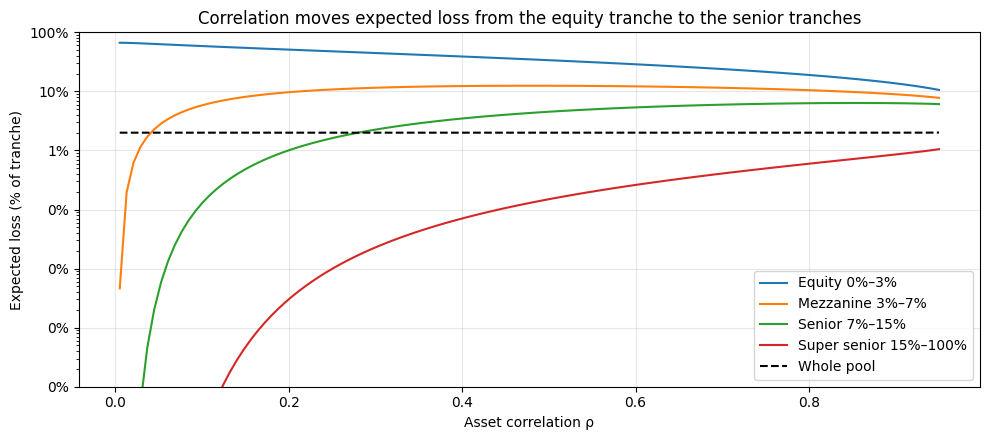

,Equity,Mezzanine,Senior,Super senior,Whole pool (check)
ρ = 0.05,62.8538%,2.8479%,0.0058%,0.0000%,2.0000%
ρ = 0.15,54.7250%,8.0195%,0.4639%,0.0004%,2.0000%
ρ = 0.30,44.7038%,11.5156%,2.2395%,0.0225%,2.0000%
ρ = 0.50,33.8789%,12.4675%,4.4995%,0.1470%,2.0000%


In [3]:
def tranche_metrics(a, d, p, rho, lgd, n_grid=4001):
    """Expected loss (fraction of tranche notional) and probability of any loss for tranche [a, d].

    Uses E[tranche loss] = ∫_a^d P(L > x) dx / (d - a), with the Vasicek large-pool CDF.
    """
    xs = np.linspace(a, d, n_grid)
    surv = 1 - vasicek_cdf(xs / lgd, p, rho)
    el = np.trapezoid(surv, xs) / (d - a)
    return el, surv[0]


rhos = np.linspace(0.005, 0.95, 120)
el = pd.DataFrame({name: [tranche_metrics(a, d, PD, r, LGD)[0] for r in rhos]
                   for name, (a, d) in TRANCHES.items()}, index=rhos)
widths = pd.Series({name: d - a for name, (a, d) in TRANCHES.items()})
pool_el = el.mul(widths).sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 4.5))
for name in el:
    ax.plot(el.index, el[name], label=f"{name} {TRANCHES[name][0]:.0%}–{TRANCHES[name][1]:.0%}")
ax.plot(pool_el.index, pool_el, "k--", label="Whole pool")
ax.set_yscale("log")
ax.set_ylim(1e-6, 1)
ax.set_xlabel("Asset correlation ρ")
ax.set_ylabel("Expected loss (% of tranche)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Correlation moves expected loss from the equity tranche to the senior tranches")
ax.legend()
plt.tight_layout()
plt.show()

table = el.iloc[[np.abs(rhos - r).argmin() for r in [0.05, 0.15, 0.30, 0.50]]]
table.index = [f"ρ = {r:.2f}" for r in table.index]
table["Whole pool (check)"] = pool_el.loc[el.index[[np.abs(rhos - r).argmin() for r in [0.05, 0.15, 0.30, 0.50]]]].values
display(table.style.format("{:.4%}"))

The pool's expected loss stays at exactly 2.00% for every $\rho$; the check column confirms the tranche losses add back up to it. Inside the pool, though, risk moves a lot. Raising $\rho$ from 0.05 to 0.30:

* the **equity** tranche's expected loss *falls* from 63% to 45%. With high correlation, there are more scenarios where almost no one defaults, and the equity survives.
* the **mezzanine** expected loss quadruples, from 2.8% to 11.5%.
* the **senior** expected loss rises almost 400-fold, from 0.006% to 2.2%.
* the **super-senior** tranche goes from essentially riskless to 0.02%.

This is why correlation trading existed. An equity tranche investor is long correlation, a senior investor is short correlation, and a mistake about $\rho$ is a transfer of value between them (Duffie & Gârleanu, 2001).

## 3. How fragile are tranche ratings?

Ratings are largely based on the probability that a tranche takes *any* loss, $P(L > a)$. The table shows that probability for each tranche for a range of pool default probabilities and correlations. All of these are values an analyst could plausibly have chosen before 2007.

In [4]:
def attach_prob(a, p, rho, lgd=LGD):
    """Probability that pool losses reach attachment point a (the tranche takes any loss)."""
    return 1 - vasicek_cdf(a / lgd, p, rho)


rows = []
for p in [0.04, 0.05, 0.06, 0.08]:
    for r in [0.05, 0.10, 0.20, 0.30]:
        row = {"PD": p, "ρ": r}
        for name, (a, d) in list(TRANCHES.items())[1:]:
            row[f"{name} P(hit)"] = attach_prob(a, p, r)
        rows.append(row)
frag = pd.DataFrame(rows).set_index(["PD", "ρ"])
display(frag.style.format("{:.4%}").format_index("{:.0%}", level=0).format_index("{:.2f}", level=1)
        .background_gradient(cmap="Reds", axis=None, gmap=np.log10(frag.clip(lower=1e-8))))

The senior tranche's probability of loss varies by a factor of over 100 across this table. It ranges from 0.05% (PD 5%, ρ = 0.05) to 5.8% (PD 5%, ρ = 0.30) for the *same* collateral, and reaches 12.8% at PD 8% and ρ = 0.30. The pool's expected loss only goes from 1.6% to 3.2% across the whole table. The mezzanine tranche barely reacts to correlation once it is above 0.10, because it sits in the middle of the distribution. The tails are where all the sensitivity is, and the tails are what the two hardest-to-estimate parameters control.

### How much of the deal can be AAA?

Arrangers wanted the AAA slice as large as possible, because AAA paper was cheapest to fund. Here we size the AAA tranche as the lowest attachment point with less than a 0.1% chance of any loss over 5 years. That 0.1% is a stylized standard. Then we ask what happens if the true correlation was 0.30.

In [5]:
# Size of the AAA tranche: the lowest attachment point with P(hit) below a target
AAA_TARGET = 0.001     # stylized "AAA" standard: at most a 0.1% chance of any loss over 5 years
rows = {}
for r in [0.05, 0.10, 0.20, 0.30]:
    grid = np.linspace(0.005, 0.6, 5000)
    a_star = grid[np.argmax(attach_prob(grid, PD, r) < AAA_TARGET)]
    rows[f"ρ = {r:.2f}"] = {"AAA attachment": a_star, "AAA share of deal": 1 - a_star,
                            "P(hit) if true ρ = 0.30": attach_prob(a_star, PD, 0.30)}
aaa = pd.DataFrame(rows).T
display(aaa.style.format({"AAA attachment": "{:.1%}", "AAA share of deal": "{:.1%}",
                          "P(hit) if true ρ = 0.30": "{:.2%}"}))

,AAA attachment,AAA share of deal,P(hit) if true ρ = 0.30
ρ = 0.05,6.6%,93.4%,6.57%
ρ = 0.10,9.6%,90.4%,2.69%
ρ = 0.20,15.4%,84.6%,0.53%
ρ = 0.30,20.9%,79.1%,0.10%


Assume $\rho = 0.05$, and 93% of the deal can be sold as AAA with only 6.6% subordination below it. If the true $\rho$ is 0.30, that "AAA" tranche has a 6.6% chance of loss: 66 times the standard it was sized to, and closer to a speculative-grade bond than to AAA. With correctly assumed $\rho = 0.30$, the AAA tranche needs 20.9% subordination and only 79% of the deal qualifies. The 14 percentage points in between was the arranger's gain from a low correlation assumption, and the investor's hidden risk.

## 4. CDO²: tranches of tranches

Mezzanine tranches of mortgage deals were hard to sell, so they were pooled again into "ABS CDOs", or CDO², and re-tranched. Most of the CDO² was again rated AAA. The key input was now the correlation *between the pools*. A two-level factor model captures it:

$$A_i = \sqrt{\rho_m}\,Z + \sqrt{\rho - \rho_m}\,Y_{\text{pool}} + \sqrt{1-\rho}\,\varepsilon_i,$$

where $Z$ is the national economy shared by all pools, $Y_{\text{pool}}$ is a regional factor shared within each pool, and $\rho = 0.20$ as before. The cross-pool correlation $\rho_m$ is the part that matters. With $\rho_m$ near zero, the 50 mezzanine tranches behave like independent bets, pooling diversifies them, and a large AAA slice is possible. With high $\rho_m$, all 50 tend to be wiped out together.

The arranger sizes both AAA tranches to a 0.1% probability of loss, using PD 5% and an assumed $\rho_m = 0.02$ (pools in different regions are nearly independent). The CDO² is simulated with 200,000 draws of the economy, each pool large enough to use the Vasicek formula.

In [6]:
# CDO-squared: 50 mortgage pools, each sold as a mezzanine tranche; the mezzanine tranches are pooled and re-tranched.
# Two-level factor model: A = √ρ_m Z + √(ρ − ρ_m) Y_pool + √(1 − ρ) ε, so pools share Z but also have their own Y.
N_POOLS, N_SIMS = 50, 200_000
MEZZ = TRANCHES["Mezzanine"]


def cdo2_losses(p, rho, rho_m, seed=0):
    g = np.random.default_rng(seed)
    z = g.standard_normal((N_SIMS, 1))
    y = g.standard_normal((N_SIMS, N_POOLS))
    common = (np.sqrt(rho_m) * z + np.sqrt(rho - rho_m) * y) / np.sqrt(rho)   # each pool's own factor, N(0,1)
    pool_loss = LGD * cond_pd(p, rho, common)                                 # large pools: loss = LGD · conditional PD
    a, d = MEZZ
    mezz_loss = np.clip(pool_loss - a, 0, d - a) / (d - a)                    # loss of each mezzanine tranche
    return pool_loss[:, 0], mezz_loss[:, 0], mezz_loss.mean(axis=1)


# Size both "AAA" tranches to a 0.1% hit probability under the arranger's assumptions:
# PD 5%, ρ = 0.20 inside each pool, and pools almost independent of each other (ρ_m = 0.02)
RHO, RHO_M_ASSUMED = 0.20, 0.02
_, _, base_cdo2 = cdo2_losses(PD, RHO, RHO_M_ASSUMED, seed=1)
a_cdo2 = np.quantile(base_cdo2, 1 - AAA_TARGET)
grid = np.linspace(0.005, 0.6, 20_000)
a_pool = grid[np.argmax(attach_prob(grid, PD, RHO) < AAA_TARGET)]
print(f"AAA attachment: {a_pool:.1%} of the mortgage pool; {a_cdo2:.1%} of the CDO² (pool of mezzanine tranches)")

rows = []
for rho_m in [0.02, 0.05, 0.10, 0.15]:
    for p in [0.05, 0.06]:
        _, mezz, cdo2_pool = cdo2_losses(p, RHO, rho_m, seed=2)
        rows.append({"Cross-pool ρ_m": rho_m, "PD": p,
                     "Mezzanine P(hit)": (mezz > 0).mean(),
                     "Pool AAA P(hit)": attach_prob(a_pool, p, RHO),
                     "CDO² AAA P(hit)": (cdo2_pool > a_cdo2).mean(),
                     "CDO² AAA EL": (np.clip(cdo2_pool - a_cdo2, 0, 1 - a_cdo2) / (1 - a_cdo2)).mean()})
cdo2 = pd.DataFrame(rows).set_index(["Cross-pool ρ_m", "PD"])
display(cdo2.style.format("{:.2%}").format_index("{:.2f}", level=0).format_index("{:.0%}", level=1)
        .background_gradient(subset=["CDO² AAA P(hit)"], cmap="Reds"))

AAA attachment: 15.4% of the mortgage pool; 39.7% of the CDO² (pool of mezzanine tranches)


The two AAA tranches start with the same rating at the arranger's assumptions (0.09–0.10% chance of loss) but respond very differently to errors:

* **A 1-point error in PD** (5% → 6%) roughly doubles the risk of the pool AAA (0.10% → 0.19%), but multiplies the CDO² AAA's risk by six (0.09% → 0.56%).
* **An error in cross-pool correlation** does not affect the pool AAA at all, but it is fatal to the CDO² AAA. At $\rho_m = 0.10$ its chance of loss is 5.4%, more than fifty times the target. At $\rho_m = 0.15$ with PD 6%, 12.5% of scenarios hit it, with an expected loss of 5.3%.

This is the mechanism Coval, Jurek & Stafford (2009) describe. Tranching concentrates the pool's risk into the tail. Re-tranching tranches concentrates it again, so the result depends almost entirely on parameters nobody could measure precisely. The cross-pool correlation of US house prices had never been tested by a nationwide decline before 2007.

## 5. Senior tranches are economic catastrophe bonds

The plot shows each tranche's loss as a function of the state of the economy. The x-axis is the percentile of the common factor $Z$, from the worst state (left) to the best (right).

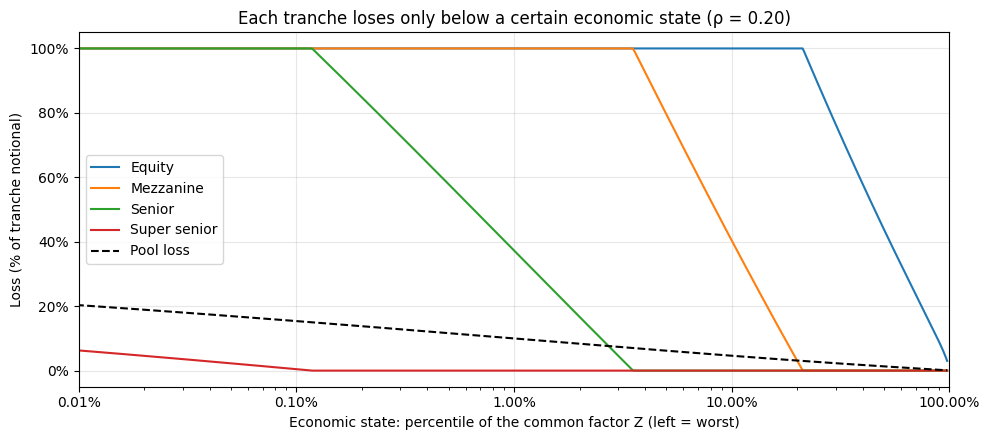

,Expected loss,Share from worst 5% of states,Share from worst 1% of states
Equity,50.99%,9.81%,1.96%
Mezzanine,9.68%,49.99%,10.33%
Senior,1.01%,100.00%,62.95%
Super senior,0.00%,100.00%,100.00%
Whole pool,2.00%,21.34%,6.16%


In [7]:
z = np.linspace(-4, 2, 601)
state_pct = norm.cdf(z)
pool_loss = LGD * cond_pd(PD, 0.20, z)
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, (a, d) in TRANCHES.items():
    ax.plot(state_pct, np.clip(pool_loss - a, 0, d - a) / (d - a), label=name)
ax.plot(state_pct, pool_loss, "k--", label="Pool loss")
ax.set_xscale("log")
ax.set_xlim(1e-4, 1)
ax.set_xlabel("Economic state: percentile of the common factor Z (left = worst)")
ax.set_ylabel("Loss (% of tranche notional)")
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=2))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Each tranche loses only below a certain economic state (ρ = 0.20)")
ax.legend()
plt.tight_layout()
plt.show()

# share of each tranche's expected loss that comes from the worst 1% and 5% of economic states
u = (np.arange(200_000) + 0.5) / 200_000
zz = norm.ppf(u)
pl = LGD * cond_pd(PD, 0.20, zz)
rows = {}
for name, (a, d) in {**TRANCHES, "Whole pool": (0.0, 1.0)}.items():
    tl = np.clip(pl - a, 0, d - a) / (d - a)
    rows[name] = {"Expected loss": tl.mean(), "Share from worst 5% of states": tl[u < 0.05].sum() / tl.sum(),
                  "Share from worst 1% of states": tl[u < 0.01].sum() / tl.sum()}
display(pd.DataFrame(rows).T.style.format("{:.2%}"))

Each tranche is effectively a bet on how bad the economy gets. The equity tranche loses in all but the best states. The mezzanine starts losing in the worst 21% of states, the senior only in the worst 3.5%, and the super senior only beyond the worst 0.1%. In the table, **all** of the senior tranche's expected loss comes from the worst 5% of states, and 63% of it from the worst 1%. For the equity tranche the figures are 10% and 2%.

Coval, Jurek & Stafford (2009, AER) point out why this matters for pricing. A corporate bond with a 1% expected loss defaults for many reasons, most of them firm-specific. A senior tranche with the same expected loss defaults *only* in a depression, when every other asset is also falling and money is most valuable. Investors should demand a much larger spread for that, but the market priced AAA tranches like AAA corporate bonds. The ratings measured the probability of loss and ignored *when* the loss happens.

## 6. Real data: what did the mortgage data say about correlation?

The model has two parameters that were the hardest to pin down: the default probability and the asset correlation. Both can be estimated from a time series of default rates. If yearly default rates follow the Vasicek distribution, then $N^{-1}(\text{DR}_t)$ is normal with mean $N^{-1}(p)/\sqrt{1-\rho}$ and variance $\rho/(1-\rho)$, which gives closed-form maximum-likelihood estimates.

The data is the Federal Reserve's quarterly **net charge-off rate on single-family residential mortgages** held by US commercial banks since 1991 (FRED series CORSFRMACBS, annualized). It is averaged to annual values. A charge-off rate measures losses, so we convert it to a default rate by dividing by an assumed loss given default.

Downloaded from FRED
140 quarters: 1991-01-01 → 2025-10-01


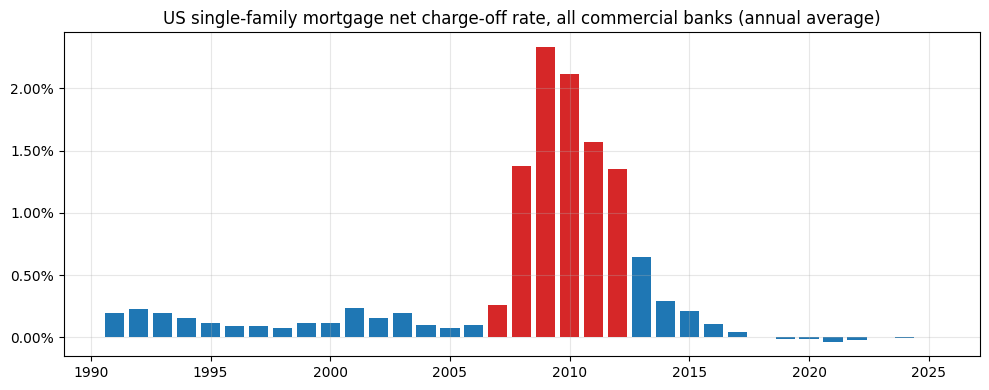

In [8]:
SRC = next(p / "src" for p in Path.cwd().resolve().parents if (p / "src" / "data.py").exists())
path = SRC / "data" / "FRED_CORSFRMACBS.csv"
try:
    co = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=CORSFRMACBS", index_col=0, parse_dates=True)
    co.to_csv(path)
    print("Downloaded from FRED")
except Exception as e:
    print(f"Download failed ({type(e).__name__}), using existing CSV in src/data")
    co = pd.read_csv(path, index_col=0, parse_dates=True)
co = co.iloc[:, 0].loc[:"2025-12-31"] / 100
annual = co.groupby(co.index.year).mean()
print(f"{len(co)} quarters: {co.index[0].date()} → {co.index[-1].date()}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(annual.index, annual, color=["tab:red" if 2007 <= y <= 2012 else "tab:blue" for y in annual.index])
ax.set_title("US single-family mortgage net charge-off rate, all commercial banks (annual average)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()
plt.show()

The picture is stark. For 16 years, from 1991 to 2006, banks lost 0.1–0.2% of mortgage balances a year. Losses then rose more than twenty-fold, to 2.3% in 2009, and stayed above 1.3% until 2012. Since 2017 *net* charge-offs have been zero or slightly negative, because recoveries on old defaults exceed new charge-offs. Those years say nothing about default rates, so the estimation stops in 2016.

The fit is run on two samples: what an analyst would have had in 2006, and the full cycle through 2016. Loss given default is uncertain (bank-held mortgages lost roughly 25–60% in default), so three values are shown. The last two columns ask how likely the 2009 loss rate was under each fitted model, and what 1-in-1,000-year default rate each model implies, the Basel 99.9% quantile.

In [9]:
def fit_vasicek(default_rates):
    """Maximum likelihood: N⁻¹(DR) is normal with mean N⁻¹(p)/√(1−ρ) and variance ρ/(1−ρ)."""
    x = norm.ppf(default_rates)
    s2 = x.var(ddof=0)
    rho = s2 / (1 + s2)
    return norm.cdf(x.mean() * np.sqrt(1 - rho)), rho


def log10_tail(level, p, rho):
    """log10 P(default rate > level) under Vasicek, computed in logs so tiny probabilities survive."""
    arg = (np.sqrt(1 - rho) * norm.ppf(level) - norm.ppf(p)) / np.sqrt(rho)
    return norm.logsf(arg) / np.log(10)


peak_year = annual.idxmax()
rows = []
for lgd_assumed in [0.25, 0.40, 0.60]:
    dr = annual / lgd_assumed
    peak = dr.loc[peak_year]
    for label, sample in [("1991–2006 (pre-crisis)", dr.loc[:2006]), ("1991–2016 (full cycle)", dr.loc[:2016])]:
        p_hat, rho_hat = fit_vasicek(sample)
        rows.append({"LGD": lgd_assumed, "Sample": label, "Annual PD": p_hat, "Asset correlation ρ": rho_hat,
                     f"log10 P(DR ≥ {peak_year} level)": log10_tail(peak, p_hat, rho_hat),
                     "99.9% default rate": norm.cdf((norm.ppf(p_hat) + np.sqrt(rho_hat) * norm.ppf(0.999))
                                                    / np.sqrt(1 - rho_hat))})
fit = pd.DataFrame(rows).set_index(["LGD", "Sample"])
display(fit.style.format({"Annual PD": "{:.2%}", "Asset correlation ρ": "{:.3f}",
                          f"log10 P(DR ≥ {peak_year} level)": "{:.1f}", "99.9% default rate": "{:.2%}"})
        .format_index("{:.0%}", level=0))
print(f"{peak_year} charge-off rate: {annual.loc[peak_year]:.2%}; Basel II residential mortgage correlation: 0.15")

2009 charge-off rate: 2.33%; Basel II residential mortgage correlation: 0.15


The conclusion does not depend on the loss-given-default assumption:

* **Fitted on 1991–2006, the asset correlation is about 0.015.** Under that model, the 2009 default rate had a probability of about $10^{-20}$, and the 1-in-1,000-year default rate was only 0.7–1.6%. Fifteen years of calm data, with almost no variation in default rates, *mechanically* produce a tiny correlation. The model was not wrong about the past; the past simply contained no housing crash.
* **Fitted on 1991–2016, the correlation is 0.13–0.16.** Ten times larger, and almost exactly the 0.15 Basel II fixed for residential mortgages. Under this model 2009 was roughly a 1-in-80-year event: severe but possible. The 1-in-1,000-year default rate is about 11% at 40% loss given default.

An estimate of correlation from a period without a crisis is not a conservative estimate. It is a statement that the sample had no crisis in it.

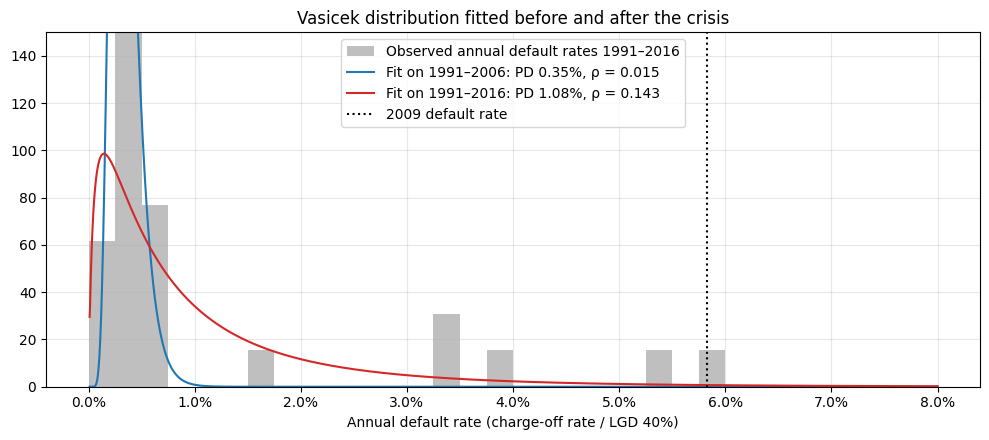

In [10]:
LGD_M = 0.40
dr = annual.loc[:2016] / LGD_M
xs = np.linspace(1e-4, 0.08, 2000)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(dr, bins=np.linspace(0, 0.08, 33), density=True, alpha=0.5, color="gray", label="Observed annual default rates 1991–2016")
for label, sample, color in [("Fit on 1991–2006", dr.loc[:2006], "tab:blue"), ("Fit on 1991–2016", dr, "tab:red")]:
    p_hat, rho_hat = fit_vasicek(sample)
    ax.plot(xs, np.gradient(vasicek_cdf(xs, p_hat, rho_hat), xs), color=color, label=f"{label}: PD {p_hat:.2%}, ρ = {rho_hat:.3f}")
ax.axvline(dr.max(), color="k", ls=":", label=f"{peak_year} default rate")
ax.set_ylim(0, 150)
ax.set_xlabel(f"Annual default rate (charge-off rate / LGD {LGD_M:.0%})")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Vasicek distribution fitted before and after the crisis")
ax.legend()
plt.tight_layout()
plt.show()

The pre-crisis fit (blue) is a narrow spike around 0.3%. The 2008–2012 default rates lie entirely outside it. The full-cycle fit (red) has the same peak but a long right tail that covers them.

### What the two models say about a mortgage AAA tranche

Finally, combine Sections 3 and 6. Take a one-year mortgage pool and size its AAA tranche with the pre-crisis estimate, so that it has a 0.02% chance of any loss in a year (the 5-year 0.1% standard spread over 5 years). Then evaluate the same tranche with the full-cycle estimate and with Basel's $\rho = 0.15$.

In [11]:
# A one-year mortgage pool tranched with the pre-crisis estimate, then re-evaluated with the full-cycle estimate
p_pre, rho_pre = fit_vasicek(dr.loc[:2006])
p_full, rho_full = fit_vasicek(dr)
grid = np.linspace(1e-4, 0.3, 30_000)
a_pre = grid[np.argmax(1 - vasicek_cdf(grid / LGD_M, p_pre, rho_pre) < AAA_TARGET / 5)]   # one-year standard: 0.02%
rows = {}
for label, p_, r_ in [("Pre-crisis model", p_pre, rho_pre), ("Full-cycle model", p_full, rho_full),
                      ("Basel ρ = 0.15, full-cycle PD", p_full, 0.15)]:
    el_, hit = tranche_metrics(a_pre, 1.0, p_, r_, LGD_M)
    rows[label] = {"AAA attachment": a_pre, "P(AAA hit) in a year": hit, "AAA expected loss": el_}
display(pd.DataFrame(rows).T.style.format({"AAA attachment": "{:.2%}", "P(AAA hit) in a year": "{:.4%}",
                                           "AAA expected loss": "{:.5%}"}))
print(f"{peak_year} pool loss: {annual.loc[peak_year]:.2%} vs AAA attachment {a_pre:.2%}")

,AAA attachment,P(AAA hit) in a year,AAA expected loss
Pre-crisis model,0.45%,0.0197%,0.00001%
Full-cycle model,0.45%,30.8798%,0.16413%
"Basel ρ = 0.15, full-cycle PD",0.45%,30.5115%,0.16829%


2009 pool loss: 2.33% vs AAA attachment 0.45%


Sized with pre-crisis data, the AAA tranche needs only 0.45% of subordination. That is about twice the worst year from 1991 to 2006. Under the full-cycle model, the same tranche is hit in 31% of years, and the actual 2009 pool loss of 2.33% would have gone five times past its attachment point. Basel's fixed $\rho = 0.15$ gives the same answer as the full-cycle estimate. A regulator's rule-of-thumb correlation, chosen without fitting to 2006 data, would have flagged this tranche as far from AAA.

This tranche is a deliberately simple illustration with a one-year horizon and prime bank-held mortgages, not a model of a real subprime deal. Subprime pools had default rates several times higher and greater sensitivity to house prices (Ashcraft & Schuermann, 2008). That only strengthens the point.

## 7. Takeaways

1. **Correlation does not change expected loss; it decides who bears it.** With the pool's expected loss fixed at 2%, raising $\rho$ from 0.05 to 0.30 cut the equity tranche's expected loss from 63% to 45% and raised the senior tranche's almost 400-fold.
2. **Senior tranche ratings are extremely fragile.** For the same collateral, the senior tranche's probability of loss ranged from 0.05% to 5.8% across plausible correlations. Assuming $\rho = 0.05$ instead of 0.30 let 93% of the deal be sold as AAA instead of 79%, and left that AAA tranche with a 6.6% chance of loss.
3. **CDO² concentrated the fragility again.** A CDO² AAA tranche sized with nearly independent pools had a 5–12% chance of loss once the cross-pool correlation was 0.10–0.15, while the ordinary pool AAA was unaffected.
4. **Senior tranches are economic catastrophe bonds.** All of the senior tranche's expected loss came from the worst 5% of economic states. A rating based on default probability alone ignores that the losses arrive exactly when everything else is also falling.
5. **The pre-crisis data could not reveal the correlation.** Mortgage charge-offs from 1991–2006 imply $\rho \approx 0.015$ and make 2009 a $10^{-20}$ event. Adding 2007–2016 gives $\rho \approx 0.14$, essentially Basel's 0.15, and makes 2009 a 1-in-80-year event.

**Next steps:** replace the Gaussian copula with a Student-t copula, whose tail dependence makes joint defaults more likely in a crisis; calibrate "base correlation" to market quotes for CDX index tranches; and add the mortgage-specific link between defaults and house prices through loan-to-value ratios, connecting this notebook with the home-equity-as-an-option ideas of Module 4.

## References

* Li, D. X. (2000). On Default Correlation: A Copula Function Approach. *Journal of Fixed Income* 9(4), 43–54.
* Duffie, D., Gârleanu, N. (2001). Risk and Valuation of Collateralized Debt Obligations. *Financial Analysts Journal* 57(1), 41–59.
* Vasicek, O. (2002). The Distribution of Loan Portfolio Value. *Risk* 15(12), 160–162.
* Gordy, M. B. (2003). A Risk-Factor Model Foundation for Ratings-Based Bank Capital Rules. *Journal of Financial Intermediation* 12(3), 199–232.
* Hull, J., White, A. (2004). Valuation of a CDO and an n-th to Default CDS Without Monte Carlo Simulation. *Journal of Derivatives* 12(2), 8–23.
* Basel Committee on Banking Supervision (2005). *An Explanatory Note on the Basel II IRB Risk Weight Functions.* BIS.
* Ashcraft, A. B., Schuermann, T. (2008). Understanding the Securitization of Subprime Mortgage Credit. *Federal Reserve Bank of New York Staff Report* 318.
* Coval, J., Jurek, J., Stafford, E. (2009). The Economics of Structured Finance. *Journal of Economic Perspectives* 23(1), 3–25.
* Coval, J., Jurek, J., Stafford, E. (2009). Economic Catastrophe Bonds. *American Economic Review* 99(3), 628–666.
* MacKenzie, D., Spears, T. (2014). 'The Formula That Killed Wall Street': The Gaussian Copula and Modelling Practices in Investment Banking. *Social Studies of Science* 44(3), 393–417.
* Board of Governors of the Federal Reserve System. Charge-Off Rate on Single Family Residential Mortgages, All Commercial Banks (CORSFRMACBS). FRED.